# Quality Factors
## Resonant Circuits and Q-factor
Resonant circuits are used extensively in oscillators, tuned amplifiers, filters, etc. At a particular frequency, _a resonant frequency_ $f_r$ (or $\omega_r$), resonators presents a maximum (or a minimum) impedance (ex: open or short circuit)[1]. The quality factor $Q$, or Q-factor, is a unitless figure of merit of the losses of a resonant passive circuit, defined as [2,3]:

$$
Q = 2 \pi \left. \frac{\textrm{Average Energy Stored}}{\textrm{Energy Loss per Second}} \right|_{\omega=\omega_r}
=
\omega_r \left. \frac{\textrm{Average Energy Stored}}{\textrm{Average Power Loss}} \right|_{\omega=\omega_r}
$$

From this definition, lower loss implies a higher $Q$. Resonators having higher Q-factors resonate with greater amplitudes (at the resonant frequency) but have a smaller range of frequencies $BW$ around that frequency for which they resonate.


## Loaded of Unloaded Q-factors
Actually, there are three Q factors than can be defined depending upon which loss is being considered [2]:

* Unloaded Q: $$Q_0 = \omega_r \left. \frac{\textrm{Energy Stored in the Resonant Circuit}}{\textrm{Power Loss in the Resonant Circuit}} \right|_{\omega=\omega_r}$$

* External Q: $$Q_e = \omega_r \left. \frac{\textrm{Energy Stored in the Resonant Circuit}}{\textrm{Power Loss in the External Circuit}} \right|_{\omega=\omega_r}$$

* Loaded Q: $$Q_L = \omega_r \left. \frac{\textrm{Energy Stored in the Resonant Circuit}}{\textrm{Total Power Loss}} \right|_{\omega=\omega_r}$$

The _loaded_ Q-factor $Q_L$, describes energy dissipation within the entire resonant system comprising of the resonator itself and the instrument used for observing resonances [3]. The term _loading_ refers to the effect that the external circuit has on measured quantities. Any loss mechanisms due to the external circuitry will have the effect of lowering the $Q$.

The _unloaded_ Q-factor $Q_0$ is a characteristic of the resonator itself, in the absence of any loading effects caused by external circuitry (uncoupled). For most applications, the quantity that is desired is the unloaded Q-factor $Q_0$ which is determined by energy dissipation associated with the resonator only and therefore gives the best description of the resonant mode. Direct measurement of the unloaded Q of a resonator is generally not possible because of the loading effect of the measurement system. However, it is possible to estimate $Q_0$ from measurements of the frequency response of the loaded resonator.

The energy dissipation in the external circuit is characterized by the _external_ Q-factor $Q_e$ and these three Q-factors are related by the relationship (deduced from the three expressions above):

$$
\frac{1}{Q_L} = \frac{1}{Q_e} + \frac{1}{Q_0} 
$$

If one defines the _coupling factor_ $\beta=Q_0/Q_e$ then:

$$
Q_0 = (1 + \beta) Q_L
$$

Three cases can be distinguished:

1. $\beta<1$: The resonator is said to be _undercoupled_ to the feeding circuitry
2. $\beta=1$: The resonator is said to be _critically coupled_
3. $\beta>1$: The resonator is said to be _overcoupled_


While the measurements of the loaded Quality factor $Q_L$ is straightforward, obtaining uncertainty below 1% (which is considered to be low for Q-factor measurement) requires attention to several aspects of the experimental procedure. In addition, finding the unloaded $Q_0$ from measured S-parameters consists in first finding the coupling factor $\beta$, then measure $Q_L$ from the 3dB bandwidth and using the relationships above.

Fortunately, `scikit-rf` implements automatic methods for determining _loaded_ and _unloaded_ Q-factors from frequency-domain S-parameters. The implemented methods are described in detail in [4], and can be applied to measurements of transmission or reflection.

## Example with a Parallel RLC Circuit
To illustrate the usage of the `Qfactor` class of `scikit-rf`, a parallel RLC circuit as illustrated above is used as an canonical example for which analytical formulas are available for benchmarking.

<img src="figures/Parallel_RLC_resonator.svg" width="300"/>

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import skrf as rf

rf.stylely()

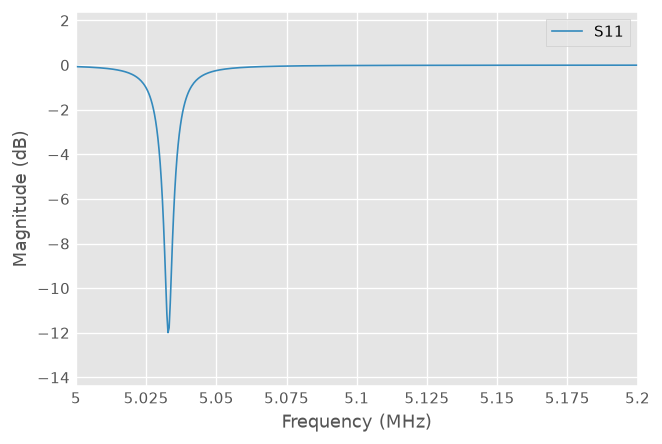

In [2]:
C = 1e-6  # F
L = 1e-9  # H
R = 30  # Ohm
Z0 = 50  # Ohm

freq = rf.Frequency(5, 5.2, npoints=501, unit='MHz')
media = rf.media.DefinedGammaZ0(frequency=freq, z0=Z0)  # ideal line (no loss)
rng = np.random.default_rng()
random_d = rng.uniform(-np.pi, np.pi)  # a random length for the sake of the example

resonator = media.line(d=random_d, unit='rad') \
                **media.shunt_inductor(L) ** media.shunt_capacitor(C) \
                ** media.shunt(media.resistor(R)**media.short()) ** media.open()

resonator.plot_s_db()

Analytical formulas for this case are available and given by [2,3]:
$$ f_{\mathrm{res}} = \frac{1}{2\pi \sqrt{L C}} $$
$$ Q = \omega_r R C = \frac{R C}{\sqrt{L C}}$$

In [3]:
def f_res_RLC(L, C):
    return 1/(2*np.pi*np.sqrt(L*C))

def Q_RLC(R, L, C):
    return R * C / np.sqrt(L*C)

The unloaded Q-factor $Q_0$ is a characteristic of the resonator itself, in the absence of any loading effects caused by the external circuitry. In practice, of course, the resonator is connected and coupled to this circuitry which have the effect to lower the Q-factor of the loaded circuit $Q_L$. 

Hence, when the resonator is connected to the transmission line, it is loaded with the port impedance $Z_0$ (assuming no loss in the transmission line), which is connected in parallel to the intrinsic resonator resistor. The equivalent resonator load is therefore $R \parallel Z_0 = (R Z_0) / (R+Z_0)$:

In [4]:
print(f'Theoretical Resonant Frequency: {f_res_RLC(L, C)/1e6} MHz')
print(f'Theoretical Loaded Q: Q_L = {Q_RLC((R*Z0)/(R+Z0), L, C)}')  # Req = R//Z0
print(f'Theoretical Unloaded Q: Q_0 = {Q_RLC(R, L, C)}')

Theoretical Resonant Frequency: 5.032921210448704 MHz
Theoretical Loaded Q: Q_L = 592.9270612815711
Theoretical Unloaded Q: Q_0 = 948.6832980505137


First, let's create a `Qfactor` object, passing the resonator Network and the type of resonator we are dealing with:

In [5]:
Q = rf.qfactor.Qfactor(resonator, res_type='reflection')

Note that in case of multiple resonances ([like in this example](../examples/qfactor/Finding_Dk_Df_from_resonance_fitting.ipynb)), it is recommended to also pass the estimated resonance frequency and eventually the estimated (order of magnitude) Q-factor.  

Then, we use the `fit` method to fit the loaded Q-factor $Q_L$ and resonant frequency. The returned results will be useful to deduce the unloaded Q-factor.

In [6]:
res = Q.fit()
print(f'Fitted Resonant Frequency: f_L = {Q.f_L/1e6} MHz')
print(f'Fitted Loaded Q-factor: Q_L = {Q.Q_L}')

Fitted Resonant Frequency: f_L = 5.032919422706801 MHz
Fitted Loaded Q-factor: Q_L = 592.9272284660681


Note that these results are also shown if you print the `Qfactor` object: 

In [7]:
Q

Q-factor of Network None. (fitted: f_L=5.033MHz, Q_L=592.927)

Finally, the unloaded Q-factor is deduced from the fitting properties: 

In [8]:
Q0 = Q.Q_unloaded(res)
print(f'Fitted Unloaded Q-factor: Q_0 = {Q0}')

Fitted Unloaded Q-factor: Q_0 = 948.6836129994118


Note that passing the result is optional. Calling the `.fit()` method will store internally the optimized results and use it if a specific optimized result is not passed:

In [9]:
Q0 = Q.Q_unloaded()  # will use the latest optimized results performed with .fit()
print(f'Fitted Unloaded Q-factor: Q_0 = {Q0}')

Fitted Unloaded Q-factor: Q_0 = 948.6836129994118


Note that the analytical results and the fitted ones match well, the relative error is small:

In [10]:
print('Relative Error on Q_0:', (Q_RLC(R, L, C) - Q0)/Q_RLC(R, L, C))

Relative Error on Q_0: -3.3198528819387325e-07


It is also possible to generate a Network from the fitted results. For example, we can compare the fitted resonator model for more frequency points to the initial RLC resonator: 

In [11]:
new_freq = rf.Frequency(5, 5.2, npoints=5001, unit='MHz')
fitted_network = Q.fitted_network(res, frequency=new_freq)

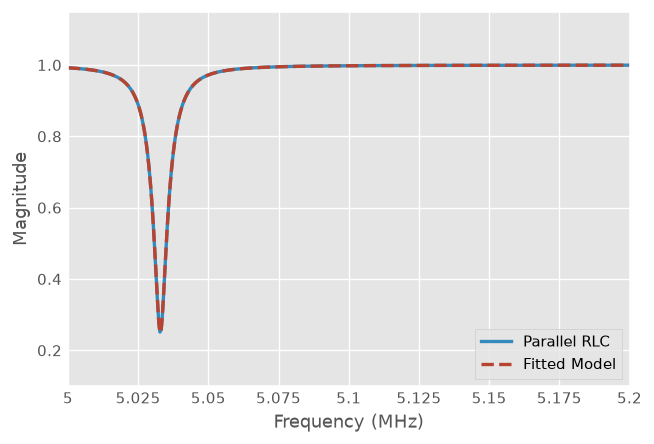

In [12]:
resonator.plot_s_mag(label='Parallel RLC ', lw=2)
fitted_network.plot_s_mag(label='Fitted Model', lw=2, ls='--')

## Q-Circle
Close to a resonance, a resonator can be represented by an equivalent circuit model [1,4]. 

The Scattering-parameters (reflection or transmission) of RF circuits including resonator(s) have the form of circles in the complex plane $(\Re(s), \Im(s))$. S-parameters can be expressed as a function of the frequency $f$, the loaded quality factor $Q_L$ [1,4]:

$$
S(f) = S_D + d \frac{e^{-2 j \delta}}{1 + j Q_L \mathcal{F}}
$$

where :
- $S_D$ is the detuned S-parameter measured at frequencies far above or below the resonance
- $Q_L$ is the loaded Q-factor
- $f_L$ is the loaded resonant frequency
- $f_0$ is the unloaded resonant frequency
- $d$ is the diameter of the Q-circle
- $\delta$ is a real valued constant that defines the orientation of the Q-circle
- $\mathcal{F}$ is the fractional offset frequency given by:
$$
\mathcal{F} = \frac{f}{f_L} - \frac{f_L}{f}
$$

The fractional frequency $\mathcal{F}$ is a convenient way to express the frequency when dealing with resonant circuits:  $\mathcal{F}=0$ at the resonant frequency and when $f<f_L$, $\mathcal{F}$ is negative, while it is positive when $f>f_L$. If $\Delta f = f - f_L$ is the frequency deviation from the resonance, then close to the resonance:

$$\mathcal{F} \approx 2 \frac{\Delta f}{f_L}$$

For example, if the source frequency is 10% below the resonant frequency ($0.9 f/f_L$), then $\mathcal{F}\approx -0.2$.

The parameters (diameters and tuned and off-tuned S-parameters) of the Q-circle can eventually be obtained from: 

In [13]:
diam, S_V, S_T = Q.Q_circle()

Use a polar plane to check the results: 

Text(2.6565127384322524, 1.1, '$S_V$')

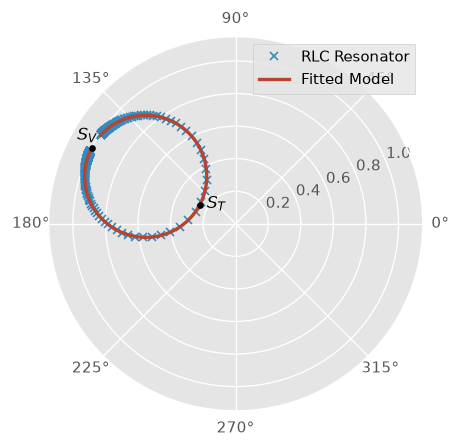

In [14]:
fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})
resonator.plot_s_polar(ax=ax, label="RLC Resonator", ls='', marker='x', ms=5)
fitted_network.plot_s_polar(ax=ax, label="Fitted Model", lw=2)
ax.plot(np.angle(S_V), np.abs(S_V), 'ko')
ax.plot(np.angle(S_T), np.abs(S_T), 'ko')
ax.text(np.angle(S_T), 0.8*np.abs(S_T), '$S_T$')
ax.text(np.angle(S_V), 1.1*np.abs(S_V), '$S_V$')

## Bandwidth
Another definition of the Q-factor is the frequency-to-bandwidth ratio of a transmission resonator [6]:

$$
Q_L = \frac{\omega_r}{\Delta \omega} = \frac{f_r}{\Delta f} 
$$

where $f_r$ is the resonant frequency, $\Delta f=BW$ is the resonance width or  _fractional bandwidth_ BW. Note that this definition is only an approximation, which can be not accurate when there is significant leakage (see [4] for more information). The definition of the bandwidth also depends on the resonator type:

* transmission:  bandwidth, also known as _full width at half maximum_ (FWHM), is the bandwidth over which the dissipated power is half the maximum value at the resonant frequency (3 dB below the max value).
* reflection: while it is possible to define the bandwidth as the 3-dB points below the max reflection coefficient [6], a more proper definition of the bandwidth consists in measuring the difference between frequencies $f_1$ and $f_2$, which belong to the two points inclined by 45 degrees on each side of the centerline from $S_T$ to the origin (see [4,8] for additional details).

Using the previous relation, the bandwidth BW can also be obtained from the `Qfactor` class via the `.BW` parameter.

In [15]:
BW = Q.BW
print(f'Bandwidth: {BW} Hz')

Bandwidth: 8488.258223065941 Hz


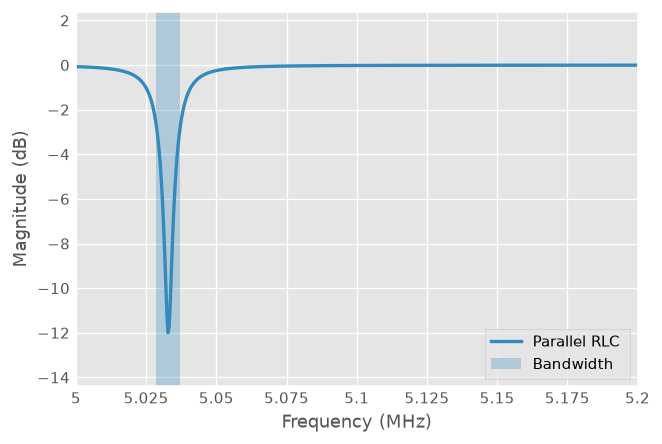

In [16]:
fig, ax = plt.subplots()
resonator.plot_s_db(label='Parallel RLC ', lw=2, ax=ax)
ax.axvspan(xmin=Q.f_L-Q.BW/2, xmax=Q.f_L+Q.BW/2, alpha=0.3, label='Bandwidth')
ax.legend()

## References
- [1] B. A. Galwas, "Scattering Matrix Description of Microwave Resonators," in IEEE Transactions on Microwave Theory and Techniques, vol. 31, no. 8, pp. 669-671, Aug. 1983, doi: 10.1109/TMTT.1983.1131566.
- [2] Peter A. Rizzi, "Microwave Engineering: Passive Circuits", Prentice-Hall, 1988 
- [3] David M. Pozar, "Microwave Engineering", 4th Edition, Éditeur	Wiley, 2011
- [4] A. P. Gregory, "Q-factor Measurement by using a Vector Network Analyser", National Physical Laboratory Report MAT 58 (2021), https://eprintspublications.npl.co.uk/9304/
- [5] Microwaves101, "Resonance of RLC Circuits", https://www.microwaves101.com/encyclopedias/resonance-of-rlc-circuits
- [6] Green, Estill I. (October 1955). "The Story of Q", American Scientist. 43: 584–594. http://www.collinsaudio.com/Prosound_Workshop/The_story_of_Q.pdf
- [7] R. S. Kwok and J.-F. Liang, ‘Characterization of high-Q resonators for microwave filter applications’, IEEE Transactions on Microwave Theory and Techniques, vol. 47, no. 1, pp. 111–114, Jan. 1999, doi: 10.1109/22.740093.
- [8] Darko Kajfez, "Q factor measurements, analog and digital", https://people.engineering.olemiss.edu/darko-kajfez/assets/rfqmeas2b.pdf
